In [1]:
# pip install ucimlrepo

In [33]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
statlog_german_credit_data = fetch_ucirepo(id=144)

# data (as pandas dataframes)
X = statlog_german_credit_data.data.features
y = statlog_german_credit_data.data.targets

In [34]:
X.head(5)

,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201


In [35]:
y.value_counts()

class
1        700
2        300
Name: count, dtype: int64

In [36]:
import pandas as pd

X = pd.DataFrame(X)
X.columns = ['Status',
             'Duration',
             'History',
             'Purpose',
             'Amount',
             'Savings',
             'Employment',
             'Installment',
             'Personal_status',
             'Debtors',
             'Residence_since',
             'Property',
             'Age',
             'Other_installments',
             'Housing',
             'Credits_number',
             'Job',
             'Liable',
             'Telephone',
             'Foreign']
X

,Status,Duration,History,Purpose,Amount,Savings,Employment,Installment,Personal_status,Debtors,Residence_since,Property,Age,Other_installments,Housing,Credits_number,Job,Liable,Telephone,Foreign
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,A14,12,A32,A42,1736,A61,A74,3,A92,A101,4,A121,31,A143,A152,1,A172,1,A191,A201
996,A11,30,A32,A41,3857,A61,A73,4,A91,A101,4,A122,40,A143,A152,1,A174,1,A192,A201
997,A14,12,A32,A43,804,A61,A75,4,A93,A101,4,A123,38,A143,A152,1,A173,1,A191,A201
998,A11,45,A32,A43,1845,A61,A73,4,A93,A101,4,A124,23,A143,A153,1,A173,1,A192,A201


In [37]:
import numpy as np

X['Status'] = np.where(X['Status'] == 'A11', '<0DM',
                       np.where(X['Status'] == 'A12', '<200DM',
                                np.where(X['Status'] == 'A13', '>200DM', 'No Information')))

X['History'] = np.where(X['History'] == 'A30', 'No Credits taken',
                        np.where(X['History'] == 'A31', 'All credits paid',
                                 np.where(X['History'] == 'A32', 'Existing credits',
                                          np.where(X['History'] == 'A33', 'Delay', 'Critical'))))

X['Purpose'] = np.where(X['Purpose'] == 'A40', 'car',
                        np.where(X['Purpose'] == 'A41', 'car used',
                                 np.where(X['Purpose'] == 'A42', 'furniture',
                                          np.where(X['Purpose'] == 'A43', 'radio',
                                                   np.where(X['Purpose'] == 'A44', 'domestic',
                                                            np.where(X['Purpose'] == 'A45', 'repairs',
                                                                     np.where(X['Purpose'] == 'A46', 'education',
                                                                              np.where(X['Purpose'] == 'A47', 'vacation',
                                                                                       np.where(X['Purpose'] == 'A48', 'retraining',
                                                                                                np.where(X['Purpose'] == 'A49', 'business', 'others'))))))))))

X['Savings'] = np.where(X['Savings'] == 'A61', '<100DM',
                        np.where(X['Savings'] == 'A62', '<500DM',
                                 np.where(X['Savings'] == 'A63', '<1000DM',
                                          np.where(X['Savings'] == 'A64', '>1000DM', 'unknown'))))

X['Employment'] = np.where(X['Employment'] == 'A71', 'unemployed',
                           np.where(X['Employment'] == 'A72', '<1year',
                                    np.where(X['Employment'] == 'A73', '<4years',
                                             np.where(X['Employment'] == 'A74', '<7years','>7years'))))

X['Personal_status'] = np.where(X['Personal_status'] == 'A91', 'male',
                                np.where(X['Personal_status'] == 'A92', 'female',
                                         np.where(X['Personal_status'] == 'A93', 'male-single',
                                                  np.where(X['Personal_status'] == 'A94', 'male-married', 'single'))))

X['Debtors'] = np.where(X['Debtors'] == 'A101', 'none',
                        np.where(X['Debtors'] == 'A102', 'co-applicant', 'guarantor'))

X['Property'] = np.where(X['Property'] == 'A121', 'real state',
                         np.where(X['Property'] == 'A122', 'building',
                                  np.where(X['Property'] == 'A123', 'car', 'unkown')))

X['Other_installments'] = np.where(X['Other_installments'] == 'A141', 'bank',
                                   np.where(X['Other_installments'] == 'A142', 'stores', 'none'))

X['Housing'] = np.where(X['Housing'] == 'A151', 'rent',
                        np.where(X['Housing'] == 'A152', 'own', 'for free'))

X['Job'] = np.where(X['Job'] == 'A171', 'unemployed',
                    np.where(X['Job'] == 'A172', 'unskilled',
                             np.where(X['Job'] == 'A173', 'skilled', 'management')))

X['Telephone'] = np.where(X['Telephone'] == 'A191', 'none', 'yes')

X['Foreign'] = np.where(X['Foreign'] == 'A201', 'yes', 'no')

In [38]:
X.head(5)

,Status,Duration,History,Purpose,Amount,Savings,Employment,Installment,Personal_status,Debtors,Residence_since,Property,Age,Other_installments,Housing,Credits_number,Job,Liable,Telephone,Foreign
0,<0DM,6,Critical,radio,1169,unknown,>7years,4,male-single,none,4,real state,67,none,own,2,skilled,1,yes,yes
1,<200DM,48,Existing credits,radio,5951,<100DM,<4years,2,female,none,2,real state,22,none,own,1,skilled,1,none,yes
2,No Information,12,Critical,education,2096,<100DM,<7years,2,male-single,none,3,real state,49,none,own,1,unskilled,2,none,yes
3,<0DM,42,Existing credits,furniture,7882,<100DM,<7years,2,male-single,guarantor,4,building,45,none,for free,1,skilled,2,none,yes
4,<0DM,24,Delay,car,4870,<100DM,<4years,3,male-single,none,4,unkown,53,none,for free,2,skilled,2,none,yes


In [39]:
X['y'] = y
X['y'] = np.where(X['y'] == 1, 1, 0)

In [40]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Status              1000 non-null   object
 1   Duration            1000 non-null   int64 
 2   History             1000 non-null   object
 3   Purpose             1000 non-null   object
 4   Amount              1000 non-null   int64 
 5   Savings             1000 non-null   object
 6   Employment          1000 non-null   object
 7   Installment         1000 non-null   int64 
 8   Personal_status     1000 non-null   object
 9   Debtors             1000 non-null   object
 10  Residence_since     1000 non-null   int64 
 11  Property            1000 non-null   object
 12  Age                 1000 non-null   int64 
 13  Other_installments  1000 non-null   object
 14  Housing             1000 non-null   object
 15  Credits_number      1000 non-null   int64 
 16  Job                 1000 

In [41]:
# Procesamiento para el input de la red
from sklearn.preprocessing import StandardScaler

X_numeric = X.select_dtypes(['int64'])
columnas = X_numeric.columns
scaler = StandardScaler()
scaler.fit(X_numeric)

X_numeric = pd.DataFrame(scaler.transform(X_numeric), columns = columnas)
X_numeric.head(5)

,Duration,Amount,Installment,Residence_since,Age,Credits_number,Liable
0,-1.236478,-0.745131,0.918477,1.046987,2.766456,1.027079,-0.428290
1,2.248194,0.949817,-0.870183,-0.765977,-1.191404,-0.704926,-0.428290
2,-0.738668,-0.416562,-0.870183,0.140505,1.183312,-0.704926,2.334869
3,1.750384,1.634247,-0.870183,1.046987,0.831502,-0.704926,2.334869
4,0.256953,0.566664,0.024147,1.046987,1.535122,1.027079,2.334869


In [42]:
X_categorical = X.select_dtypes(['object'])
X_categorical = pd.get_dummies(X_categorical, dtype = int, drop_first=True)
X_categorical.head(5)

,Status_<200DM,Status_>200DM,Status_No Information,History_Critical,History_Delay,History_Existing credits,History_No Credits taken,Purpose_car,Purpose_car used,Purpose_domestic,...,Property_unkown,Other_installments_none,Other_installments_stores,Housing_own,Housing_rent,Job_skilled,Job_unemployed,Job_unskilled,Telephone_yes,Foreign_yes
0,0,0,0,1,0,0,0,0,0,0,...,0,1,0,1,0,1,0,0,1,1
1,1,0,0,0,0,1,0,0,0,0,...,0,1,0,1,0,1,0,0,0,1
2,0,0,1,1,0,0,0,0,0,0,...,0,1,0,1,0,0,0,1,0,1
3,0,0,0,0,0,1,0,0,0,0,...,0,1,0,0,0,1,0,0,0,1
4,0,0,0,0,1,0,0,1,0,0,...,1,1,0,0,0,1,0,0,0,1


In [43]:
# axis = 1 -> Que la concatenacion se hara por columnas, si se usara por axis = 0 se haria por filas

X_data = pd.concat([X_numeric, X_categorical], axis = 1)
X_data.head(5)

,Duration,Amount,Installment,Residence_since,Age,Credits_number,Liable,Status_<200DM,Status_>200DM,Status_No Information,...,Property_unkown,Other_installments_none,Other_installments_stores,Housing_own,Housing_rent,Job_skilled,Job_unemployed,Job_unskilled,Telephone_yes,Foreign_yes
0,-1.236478,-0.745131,0.918477,1.046987,2.766456,1.027079,-0.428290,0,0,0,...,0,1,0,1,0,1,0,0,1,1
1,2.248194,0.949817,-0.870183,-0.765977,-1.191404,-0.704926,-0.428290,1,0,0,...,0,1,0,1,0,1,0,0,0,1
2,-0.738668,-0.416562,-0.870183,0.140505,1.183312,-0.704926,2.334869,0,0,1,...,0,1,0,1,0,0,0,1,0,1
3,1.750384,1.634247,-0.870183,1.046987,0.831502,-0.704926,2.334869,0,0,0,...,0,1,0,0,0,1,0,0,0,1
4,0.256953,0.566664,0.024147,1.046987,1.535122,1.027079,2.334869,0,0,0,...,1,1,0,0,0,1,0,0,0,1


In [44]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Status              1000 non-null   object
 1   Duration            1000 non-null   int64 
 2   History             1000 non-null   object
 3   Purpose             1000 non-null   object
 4   Amount              1000 non-null   int64 
 5   Savings             1000 non-null   object
 6   Employment          1000 non-null   object
 7   Installment         1000 non-null   int64 
 8   Personal_status     1000 non-null   object
 9   Debtors             1000 non-null   object
 10  Residence_since     1000 non-null   int64 
 11  Property            1000 non-null   object
 12  Age                 1000 non-null   int64 
 13  Other_installments  1000 non-null   object
 14  Housing             1000 non-null   object
 15  Credits_number      1000 non-null   int64 
 16  Job                 1000 

In [45]:
X['y'].value_counts()

y
1    700
0    300
Name: count, dtype: int64

In [46]:
pip install --upgrade scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [47]:
from sklearn.model_selection import train_test_split
y = X['y']

X_train, X_test, y_train, y_test = train_test_split(X_data, y, test_size = 0.3, random_state=1234)

In [2]:
# pip install scikeras

Note: you may need to restart the kernel to use updated packages.


In [48]:
import keras
import scikeras
from scikeras.wrappers import KerasClassifier
from tensorflow.keras.layers import Dense, Dropout  # Change here
from tensorflow.keras.optimizers import SGD, Adadelta, Adagrad
from keras.models import Sequential
from keras.initializers import HeNormal
from keras.constraints import max_norm
from keras.regularizers import l1, l2

In [49]:
for idx, hl in enumerate(range(1, 5)):
    print(idx, hl)

0 1
1 2
2 3
3 4


In [50]:
# n_features -> cuantas caracteristicas tienen mis datos, cuantas columnas tengo en mi base de datos inicial
# activations -> que activaciones voy a ocupar para cada una de las capas
# n_hidden_layers -> cuantas capas ocultas voy a ocupar
# n_neurons -> cuantas neuronas va a tener cada una de las capas ocultas
# k_initializer -> el inicializador que voy a utilizar, por efecto se usa Henormal()
# bias_initializer -> el inicializador del sesgo que ocupare

def create_model(n_features, activations, n_hidden_layers, n_neurons,
                 k_initializer=HeNormal(), bias_initializer='zeros'):

    ann1 = Sequential()

    # define la capa de entrada del modelo, especificando el tamaño del vector de entrada (con dimension n-features)
    ann1.add(keras.Input(shape=(n_features, )))

    # restriccion que le estas poniendo a la red -> esto lo pueden cambiar o dejar parametrizado arriba.
    constraint = max_norm(3)

    # Te recorre las capas ocultas
    # Le vas a agregar a cada capa oculta una capa densa la cantidad de neuronas que le di arriba, use_bias = True para que use sesgo,
    # activations[idx] -> las funciones de activacion que le voy a dar
    # k_initializer[idx] -> el inicializador del kernel
    # bias_initializer[idx] -> el inicializador del bias
    # el constraint -> el constrain que habiamos definido previamente que era la restriccion.

    # Bucle para agregar capas ocultas
    # En cada iteracion, añade una capa (Dense) con las siguientes caracteristicas
    
    for idx, hl in enumerate(range(1, n_hidden_layers+1)):
        ann1.add(
            Dense(
                units=n_neurons[idx], # Establece el numero de neuronas en ese capa, segun el indice idx
                use_bias=True, # se activa el uso de un termino (bias) en cada neurona
                activation=activations[idx], # usa la funcion de activacion correspondiente en la lista activations segun el indice idx para esa capa
                kernel_initializer=k_initializer[idx], # inicializa los pesos de la capa con el inicializador especificado para cada capa
                bias_initializer=bias_initializer[idx], # inicializa los sesgos de la capa
                kernel_constraint=constraint # aplica la restriccion max_norm(3) para los pesos
            )
        )


    # la capa de salida que es de una unidad -> units = 1, solo una neurona en la capa de salida porque estoy en una clasificacion binomial
    # Tambien que tengas bias
    # activation = sigmoid -> para que la salida se me sea mas facil de interpretar. En clasificacion binaria, 
    # la función sigmoide facilita la interpretación de la salida como una probabilidad (entre 0 y 1).
    # kernel_initializer -> inicializas los pesos con el inicializador Glorot
    # bias_initializer -> inicializa los sesgos con valores de 0.
    # constraint -> Aplica la restricción max_norm(3) también a esta capa.

    # Capa de salida
    ann1.add(
        Dense(
            units=1,
            use_bias=True,
            activation='sigmoid',
            kernel_initializer='glorot_normal',
            bias_initializer='zeros',
            kernel_constraint=constraint
        )
    )

    return ann1

activations=['tanh', 'relu', 'tanh']
- la primera capa con tanh -> tangente hiperbolica
- la segunda capa con relu ->  
- la tercera capa con tanh ->

La capa de salida
- la cuarta capa con sigmoide -> que viene a ser la capa de salida

Si quieres correr nuevamente el modelo lo debe de correr desde ann1 = create_model para que no utilices lo ya aprendido por el modelo.
- Asimismo, debes de cambiar las epocas, que es en el codigo siguiente a este.

In [51]:
ann1 = create_model(
    n_features=X_train.shape[1], # se toma el numero de columnas, caracteristicas, del conjunto de datos de entrenamiento
    activations=['tanh', 'relu', 'tanh'], # Funciones de activacion (por orden segun las capas definidas)
    n_hidden_layers=3, # Numero de capas 3 = ['tanh', 'relu', 'tanh']
    n_neurons=[20, 40, 50], # Numero de neuronas en cada capa oculta. Primera 20, 2da 40 y 3era 50
    k_initializer=['glorot_normal', 'he_normal', 'glorot_normal'], # establece los inicializadores de pesos para cada capa oculta
    bias_initializer=['glorot_uniform']*3 # inicializas los sesgos (bias) de las neuronas de todas las capas ocultas con el mismo valor: glorot_uniform
)

ann1.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_13 (Dense)                     │ (None, 20)                  │             980 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 40)                  │             840 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 50)                  │           2,050 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,921 (15.32 KB)

 Trainable params: 3,921 (15.32 KB)

 Non-trainable params: 0 (0.00 B)

- Seleccionar un learning_rate muy bajo, tendrias que aumentar mucho tus epocas.
- Seleccionar un learning_rate muy grande, nunca vas a tener un optimo local.

Procedemos ahora a configurar el modelo ann1 para ser entrenado
- Establecemos 40 epocas para el entrenamiento del modelo
- El optimizador define cómo el modelo ajusta los pesos en función del error que comete durante el entrenamiento.
- learning_rate=0.01 -> Un valor más pequeño (como 0.01) indica que el modelo ajustará los pesos de manera más gradual.
- binary_crossentropy: Es la función de pérdida adecuada para tareas de clasificación binaria (donde solo hay dos clases). Se usa típicamente en combinación con una activación sigmoid en la capa de salida, que proporciona probabilidades entre 0 y 1.
- Las métricas son las estadísticas que se calculan durante el entrenamiento y la evaluación del modelo para supervisar su rendimiento. Accuracy: Es la métrica elegida para evaluar el modelo. Mide el porcentaje de predicciones correctas (es decir, cuántas veces el modelo clasificó correctamente).


**Este proceso de compilación es necesario antes de entrenar el modelo, ya que le dice a Keras qué criterios usar para ajustar los pesos y evaluar su rendimiento.**

In [52]:
EPOCHS=40

ann1.compile(
    optimizer=SGD(learning_rate=0.01),
    loss='binary_crossentropy', # entropia cruzada para clasificacion binaria
    metrics=['accuracy']
)

validation_split

El conjunto de validacion -> es para evitar sobre ajuste


- val_accuracy -> precision en el conjunto de validacion
- val_loss -> perdida en el conjunto de validacion

-----------------------------------------------------------

El resultado de este entrenamiento se almacena en el objeto history1. Este objeto contendrá los datos sobre el rendimiento del modelo durante el entrenamiento, como la pérdida y las métricas para cada época.

batch_size = 100
- El tamaño del batch (o tamaño del lote) determina cuántos ejemplos se procesarán antes de actualizar los pesos del modelo. En este caso, 100 ejemplos se utilizarán en cada actualización.
- Esto significa que, dentro de cada época, los datos se dividirán en grupos de 100 muestras, y el modelo actualizará sus pesos después de procesar cada lote.

validation_split=.30
- Este parámetro indica que el 30% del conjunto de datos de entrenamiento se reservará para validación.
- Durante el entrenamiento, Keras separa el 30% de X_train y y_train para usarlos como datos de validación, lo que significa que el modelo entrenará con el 70% de los datos y evaluará su rendimiento en el 30% restante en cada época.
- Esto es útil para monitorear si el modelo está sobreajustando (overfitting) a los datos de entrenamiento, ya que evalúa su desempeño en datos no vistos durante el entrenamiento.

Breve resumen del codigo
1. Entrena el modelo ann1 usando los datos X_train (entrada) y y_train (etiquetas), entrenando durante 40 épocas.
2. En cada época:
- El modelo procesa lotes de 100 ejemplos.
- Actualiza los pesos después de cada lote.
- Evalúa su rendimiento en el 30% de los datos reservados para validación.
3. El resultado del entrenamiento se almacena en history1, que incluirá la evolución de la pérdida y las métricas de precisión tanto en los datos de entrenamiento como en los de validación.

In [53]:
history1 = ann1.fit(
    X_train,
    y_train,
    epochs=EPOCHS,
    batch_size=100,
    verbose=1,
    validation_split=.30
)

Epoch 1/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 0.5654 - loss: 0.6998 - val_accuracy: 0.6588 - val_loss: 0.6328
Epoch 2/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5971 - loss: 0.6913 - val_accuracy: 0.6635 - val_loss: 0.6190
Epoch 3/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6027 - loss: 0.6842 - val_accuracy: 0.6825 - val_loss: 0.6080
Epoch 4/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6423 - loss: 0.6691 - val_accuracy: 0.6967 - val_loss: 0.6001
Epoch 5/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6522 - loss: 0.6571 - val_accuracy: 0.7014 - val_loss: 0.5935
Epoch 6/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6529 - loss: 0.6561 - val_accuracy: 0.7109 - val_loss: 0.5881
Epoch 7/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6407 - loss: 0.6673 - val_accuracy: 0.7109 - val_loss: 0.5830
Epoch 8/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6675 - loss: 0.6488 - val_accuracy: 0.7156 - val_loss: 0.5790


El objeto history1 contiene información detallada sobre el entrenamiento. Puedes acceder a estos datos con history1.history, que es un diccionario que incluye:
- 'loss': Pérdida en los datos de entrenamiento en cada época.
- 'accuracy': Precisión en los datos de entrenamiento en cada época.
- 'val_loss': Pérdida en los datos de validación en cada época.
- 'val_accuracy': Precisión en los datos de validación en cada época.

Este objeto es muy útil para visualizar el comportamiento del modelo, como gráficas de la pérdida y la precisión a lo largo del tiempo.

In [54]:
history1.history

{'accuracy': [0.5787321329116821,
  0.6032719612121582,
  0.615541934967041,
  0.6380367875099182,
  0.6421267986297607,
  0.6441717743873596,
  0.6462167501449585,
  0.650306761264801,
  0.6523517370223999,
  0.6584867238998413,
  0.6625766754150391,
  0.6625766754150391,
  0.6605316996574402,
  0.6625766754150391,
  0.6646216511726379,
  0.6687116622924805,
  0.6687116622924805,
  0.6707566380500793,
  0.6728016138076782,
  0.6748466491699219,
  0.6830266118049622,
  0.685071587562561,
  0.685071587562561,
  0.6871165633201599,
  0.685071587562561,
  0.6830266118049622,
  0.6830266118049622,
  0.685071587562561,
  0.6871165633201599,
  0.6891615390777588,
  0.6891615390777588,
  0.6891615390777588,
  0.6891615390777588,
  0.6891615390777588,
  0.6912065148353577,
  0.6932515501976013,
  0.6952965259552002,
  0.6932515501976013,
  0.6932515501976013,
  0.6952965259552002],
 'loss': [0.6963675618171692,
  0.6849616765975952,
  0.6762783527374268,
  0.6693646311759949,
  0.6640991568565

In [21]:
from sklearn.metrics import classification_report, roc_curve, roc_auc_score

yhat = ann1.predict(X_test)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


In [ ]:
# yhat -> te va a salir entre 0 y 1, porque a la capa de salida le habias dado una funcion sigmoide.

In [22]:
yhat_class = np.where(yhat > 0.5, 1, 0)

print(classification_report(y_test, yhat_class))

              precision    recall  f1-score   support

           0       0.57      0.13      0.21        94
           1       0.71      0.96      0.81       206

    accuracy                           0.70       300
   macro avg       0.64      0.54      0.51       300
weighted avg       0.66      0.70      0.62       300



Resumen:

Este código genera dos gráficos:
1. Uno muestra la precisión del modelo en los conjuntos de entrenamiento y validación a lo largo de las épocas.
2. El otro muestra la pérdida del modelo para en los conjuntos de entrenamiento y validación a lo largo de las épocas.

Estos gráficos son útiles para evaluar el rendimiento del modelo, y permiten detectar sobreajuste (overfitting) o bajo ajuste (underfitting) si hay diferencias significativas entre las curvas de entrenamiento y validación.

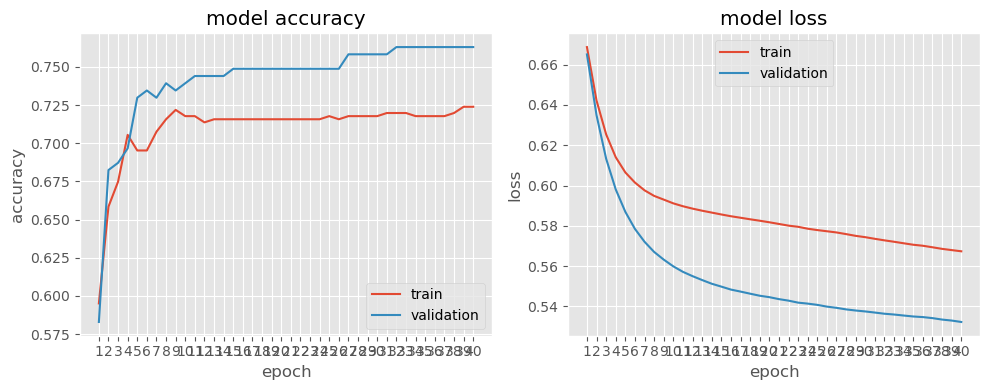

In [23]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

def viz_loss(history):
    plt.style.use('ggplot')
    epochs_ = len(history['accuracy'])
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))

    # accuracy
    ax[0].plot(history['accuracy'])
    ax[0].plot(history['val_accuracy'])
    ax[0].set_xticks(np.arange(epochs_), np.arange(1, epochs_+1))
    ax[0].set_title('model accuracy')
    ax[0].set_ylabel('accuracy')
    ax[0].set_xlabel('epoch')
    ax[0].legend(['train', 'validation'], loc='lower right')

    # loss
    ax[1].plot(history['loss'])
    ax[1].plot(history['val_loss'])
    ax[1].set_xticks(np.arange(epochs_), np.arange(1, epochs_+1))
    ax[1].set_title('model loss')
    ax[1].set_ylabel('loss')
    ax[1].set_xlabel('epoch')
    ax[1].legend(['train', 'validation'], loc='upper center')

    plt.tight_layout()
    plt.show()

viz_loss(history1.history)

- Si ves en el grafico mientras va aprendiendo, va mejorando prediccion (accuracy)

Debido a que el conjunto de validacion actua sobre el conjunto de entrenamiento, se espera que ambas lineas de entrenamiento y de validacion vayan de la mano. Es decir, vayan juntas.

- El

Hagamos otra red

In [24]:
ann2 = create_model(
    n_features=X_train.shape[1],
    activations=['relu']*3,
    n_hidden_layers=3,
    n_neurons=[100,40,50],
    k_initializer=['glorot_normal']*3,
    bias_initializer=['glorot_uniform']*3
)

ann2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 100)                 │           4,900 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 40)                  │           4,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 50)                  │           2,050 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,041 (43.13 KB)

 Trainable params: 11,041 (43.13 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
EPOCHS=100

ann2.compile(
    optimizer=SGD(learning_rate=0.01),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history2 = ann2.fit(
    X_train, y_train, epochs=EPOCHS,
    batch_size=500,
    verbose=1,
    validation_split=.33
)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.4551 - loss: 0.7060 - val_accuracy: 0.4741 - val_loss: 0.7036
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.4701 - loss: 0.7028 - val_accuracy: 0.5000 - val_loss: 0.6994
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.4957 - loss: 0.6997 - val_accuracy: 0.5302 - val_loss: 0.6954
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.5192 - loss: 0.6967 - val_accuracy: 0.5603 - val_loss: 0.6915
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.5406 - loss: 0.6939 - val_accuracy: 0.5819 - val_loss: 0.6877
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.5577 - loss: 0.6912 - val_accuracy: 0.5905 - val_loss: 0.6841
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.5641 - loss: 0.6885 - val_accuracy: 0.5862 - val_loss: 0.6806
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.5684 - loss: 0.6860 - val_accuracy: 0.5948 - val_loss: 0

In [26]:
yhat = ann2.predict(X_test)
yhat_class = np.where(yhat > 0.5, 1, 0)

print(classification_report(y_test, yhat_class))

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        94
           1       0.69      1.00      0.81       206

    accuracy                           0.69       300
   macro avg       0.34      0.50      0.41       300
weighted avg       0.47      0.69      0.56       300



C:\Users\josek\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\josek\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\josek\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


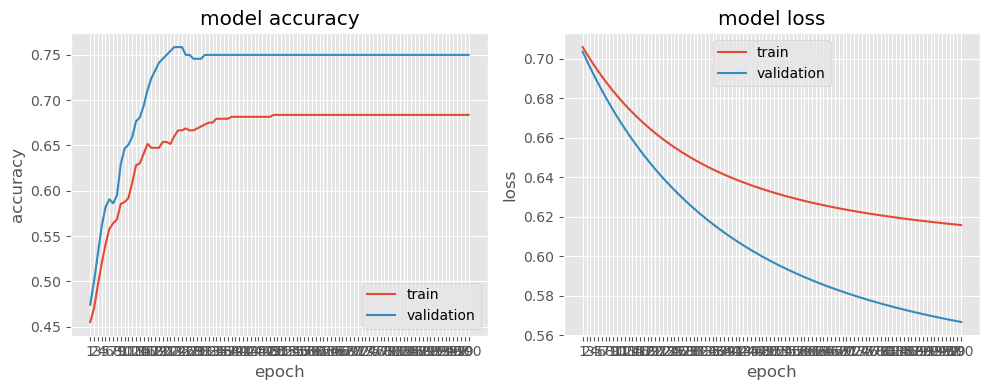

In [27]:
viz_loss(history2.history)

- meta["n_features_in_"] -> cantidad de parametros de entrada o de las variables que entran
- meta["X_shape_"] -> la forma
- 


parametros de entrada:
- n_hidden_layers: Número de capas ocultas (por defecto es 2).
- n_neurons: Número de neuronas en cada capa oculta (por defecto es 80).
- activation: Función de activación que se usará en cada capa oculta (por defecto es 'relu').
- dropout_rate: Tasa de dropout, una técnica para regularizar el modelo, eliminando aleatoriamente algunas neuronas durante el entrenamiento para evitar el sobreajuste (por defecto es 0.001)
- meta: Un diccionario que contiene información adicional sobre las características de los datos de entrada, como el número de características y la forma de los datos.

2. obtencion de la informacion desde meta
- n_features_in_ -> Número de características (columnas) del conjunto de datos de entrada.
- X_shape_ -> Forma del conjunto de datos, aunque en este código no parece que se utilice directamente.

3. aplicamos restriccion de los pesos
- constraint = max_norm(3)

4. Creación del modelo secuencial
- ann_tmp = Sequential()

5. Capa de entrada
- ann_tmp.add(keras.Input(shape=(n_features_in_, ))) -> añade una capa de entrada que especifica la forma de los datos de entrada. En este caso, se espera un vector con n_features_in_ características.

6. Capas ocultas
- Se utiliza un bucle for que recorre cada capa oculta (de acuerdo con el número de capas especificado en n_hidden_layers).
- ann_tmp.add( Dropout(rate=dropout_rate)) # Se ha añadido un dropout, que es una técnica de regularización que apaga aleatoriamente un porcentaje de neuronas durante cada paso de entrenamiento (tasa de dropout_rate, por defecto 0.001).

7. Capa de salida
- units=1: Una sola neurona de salida, adecuada para tareas de clasificación binaria (una salida de 0 o 1).
- activation='sigmoid': La función de activación sigmoide, que convierte la salida en un valor entre 0 y 1 (probabilidad), típico de los problemas de clasificación binaria.
- kernel_regularizer=l1(l1=0.001) -> Añade una regularización de tipo L1, que penaliza los pesos grandes, favoreciendo una solución más dispersa.
- kernel_constraint=constraint: Aplica nuevamente la restricción de norma máxima en los pesos de la capa.

8. Retorno del modelo
- return ann_tmp -> Devuelve el modelo ann_tmp con todas las capas definidas.

In [28]:
# Grilla
def create_model_grilla(n_hidden_layers=2, n_neurons=80,
                        activation='relu', dropout_rate=.001,
                        k_initializer='glorot_normal', meta={}):


    # obtencion de la informacion desde meta
    n_features_in_ = meta["n_features_in_"]
    X_shape_ = meta["X_shape_"]

    # Restricción para garantizar que la norma de cada
    # vector de pesos no exceda de tres.
    constraint = max_norm(3)

    # Arquitectura secuencial
    ann_tmp = Sequential()

    # Capa de entrada
    ann_tmp.add(keras.Input(shape=(n_features_in_, )))

    # Capas ocultas
    for hl in range(n_hidden_layers):
        ann_tmp.add(
            Dense(
                units=n_neurons,
                use_bias=True,
                activation=activation,
                kernel_initializer=k_initializer,
                bias_initializer='glorot_uniform',
                #kernel_regularizer=l2(l2=0.001),
                kernel_constraint=constraint
            )
        )
        ann_tmp.add(
            Dropout(rate=dropout_rate)
        )

    # Capa de salida
    ann_tmp.add(
        Dense(
            units=1,
            use_bias=True,
            activation='sigmoid',
            kernel_initializer='glorot_normal',
            bias_initializer='glorot_uniform',
            kernel_regularizer=l1(l1=0.001),
            kernel_constraint=constraint
        )
    )

    return ann_tmp

Creamos un clasificador de Keras usando la función KerasClassifier de la biblioteca scikit-learn, que es una envoltura (wrapper) para utilizar modelos de Keras como si fueran clasificadores típicos de scikit-learn.

- KerasClassifier: Esta es una clase de scikit-learn que permite integrar modelos de redes neuronales de Keras dentro del marco de trabajo de scikit-learn. Esto es útil porque permite usar funcionalidades como la validación cruzada (cross-validation), la búsqueda en grilla (GridSearchCV), o la búsqueda aleatoria (RandomizedSearchCV) con redes neuronales.
- clf: Es el nombre del objeto que almacenará el clasificador Keras creado.
- create_model_grilla -> es el primer parámetro de KerasClassifier es una función que construye el modelo.  En este caso, es la función create_model_grilla (que ya explicamos antes). Esta función define la arquitectura del modelo de red neuronal, incluyendo las capas ocultas, las funciones de activación, la tasa de dropout, la regularización, entre otras configuraciones. create_model_grilla se llama automáticamente para crear el modelo cuando entrenes el clasificador.

##### Demas parametros
- loss='binary_crossentropy' -> definimos la funcion de perdida que se usara en el modelo, en este caso, binary_crossentropy es una función de pérdida común para problemas de clasificación binaria. Mide la diferencia entre las etiquetas reales (0 o 1) y las probabilidades predichas por el modelo.
- metrics: Este parámetro define las métricas adicionales que se calcularán y monitorearán durante el entrenamiento del modelo.
- validation_split=.33 -> Este parámetro define qué porcentaje del conjunto de datos de entrenamiento se reservará para validación. En este caso, el 33% de los datos de entrenamiento se utiliza para validar el modelo en cada época, y el 67% restante se usa para entrenarlo.


In [29]:
clf = KerasClassifier(
    create_model_grilla, # Llamamos a la funcion que tiene la red con las caracteristicas
    loss='binary_crossentropy', 
    verbose=1,
    metrics=['accuracy'],
    validation_split=.33,
)

Ese clasificador clf se lo puedes pasar a GridSearch porque Keras viene listo con Scikitlearn.

3. Configuracion de GridSearchCV
- estimator=clf -> El modelo que se utilizará para realizar la búsqueda en grilla. En este caso, es el clasificador Keras (clf) que fue definido previamente.
- param_grid=param_grid -> La grilla de hiperparámetros que hemos definido. GridSearchCV probará todas las combinaciones posibles de estos hiperparámetros.
- scoring='accuracy' -> La métrica que se utilizará para evaluar las diferentes combinaciones de hiperparámetros. En este caso, se usará la precisión (accuracy), que mide qué porcentaje de las predicciones del modelo son correctas.
- cv=3: Utiliza validación cruzada con 3 "folds". Esto significa que, para cada combinación de hiperparámetros, los datos se dividirán en 3 partes y el modelo se entrenará y evaluará 3 veces, usando una parte como datos de validación y las otras dos como datos de entrenamiento.
- verbose=0: Controla el nivel de detalle que se imprime en la consola durante el proceso de búsqueda. 0 significa que no se imprime información.

4. Ajuste del modelo GridSearchCV
- grid.fit(X_train, y_train): Se ajusta el clasificador Keras (clf) con todas las combinaciones de hiperparámetros especificadas en param_grid usando el conjunto de datos de entrenamiento X_train y y_train
- El resultado se almacena en grid_result, que contiene la mejor combinación de hiperparámetros y las métricas de rendimiento.


5. Mostrar los mejores hiperparámetros
print("\n\nBest: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
- grid_result.best_score_: Devuelve el mejor puntaje obtenido en la validación cruzada, es decir, la precisión más alta lograda con la mejor combinación de hiperparámetros.
- grid_result.best_params_: Devuelve el conjunto de hiperparámetros que produjo el mejor resultado.

##### En resumen
Este código realiza una búsqueda exhaustiva (Grid Search) sobre un conjunto de hiperparámetros para encontrar la mejor combinación que optimice el rendimiento de un modelo de red neuronal, utilizando validación cruzada. GridSearchCV evalúa todas las combinaciones de los hiperparámetros y selecciona la que maximiza la métrica de evaluación (en este caso, la precisión).


In [30]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'model__n_hidden_layers': [3, 4], # Número de capas ocultas en el modelo. Se probarán 3 y 4 capas.
    'model__n_neurons': [20],  # Número de neuronas en cada capa oculta. En este caso, se probará con 20 neuronas en cada capa.
    'model__activation': ['tanh'], # Función de activación a usar en las capas ocultas. Se probará solo con la función de activación tanh en este caso.
    'batch_size': [500], # Tamaño del batch o lote (número de ejemplos que se procesan antes de actualizar los pesos). Se probará con un tamaño de lote de 500.
    'epochs': [10], # Número de épocas de entrenamiento. Aquí solo se probará con 10 épocas.
    'optimizer': ['SGD', 'adagrad'], # se probarán dos optimizadores: SGD (Stochastic Gradient Descent) y adagrad.
    'optimizer__learning_rate': [0.03, 0.06], # Se probarán dos tasas de aprendizaje (learning rate) para los optimizadores: 0.03 y 0.06.
    'model__dropout_rate': [0.001], # Tasa de dropout que se usará en las capas. Aquí se probará con un valor de 0.001.
    'model__k_initializer': ['glorot_normal', 'glorot_uniform'] # Inicializadores para los pesos de las capas. Se probarán dos inicializadores: glorot_normal y glorot_uniform.
}

# GridSearchCV
grid = GridSearchCV(estimator=clf, param_grid=param_grid,
    scoring='accuracy', cv=3, verbose=0, n_jobs=-1)

grid_result = grid.fit(X_train, y_train)

# Mostrar mejores hiper parámetros encontrados
print("\n\nBest: %f using %s" % (grid_result.best_score_, grid_result.best_params_))

Epoch 1/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.3162 - loss: 1.1547 - val_accuracy: 0.2500 - val_loss: 0.9524
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.3162 - loss: 0.9185 - val_accuracy: 0.3319 - val_loss: 0.7894
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.3654 - loss: 0.7852 - val_accuracy: 0.5603 - val_loss: 0.6978
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.5385 - loss: 0.7145 - val_accuracy: 0.6293 - val_loss: 0.6459
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.5833 - loss: 0.6775 - val_accuracy: 0.7155 - val_loss: 0.6159
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.6325 - loss: 0.6564 - val_accuracy: 0.7500 - val_loss: 0.5977
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.6560 - loss: 0.6448 - val_accuracy: 0.7716 - val_loss: 0.5861
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.6624 - loss: 0.6406 - val_accuracy: 0.7716 - val_loss: 0.57

In [31]:
yhat_class = grid_result.best_estimator_.predict(X_test)
print(classification_report(y_test, yhat_class))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
              precision    recall  f1-score   support

           0       0.80      0.04      0.08        94
           1       0.69      1.00      0.82       206

    accuracy                           0.70       300
   macro avg       0.75      0.52      0.45       300
weighted avg       0.73      0.70      0.59       300



- **Precisión (Precision)**: El porcentaje de veces que el modelo predijo correctamente la clase positiva (o negativa).
- **Recall (Sensibilidad)**: El porcentaje de veces que el modelo identificó correctamente los verdaderos positivos.
- **F1-Score**: El promedio ponderado entre precisión y recall.
- **Accuracy (Exactitud)**: Es la fracción de predicciones correctas sobre el total de predicciones.
- **Soporte**: Número de muestras reales de cada clase.


- El resultado, yhat_proba, es un array que contiene las probabilidades predichas para la clase positiva (1) para cada muestra en X_test.
-  AUC (Area Under the Curve) de la curva ROC -> es una métrica que representa el rendimiento global del modelo. Un AUC de 0.5 significa que el modelo no es mejor que una predicción aleatoria. 
Un AUC cercano a 1 indica que el modelo tiene un muy buen rendimiento
-  `label=f'auc= {auc}'`: Añade una etiqueta a la curva indicando el valor del AUC.
-  Si la curva ROC del modelo se acerca mucho a linea diagonal recta, significa que el modelo no es mejor que una predicción aleatoria..

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


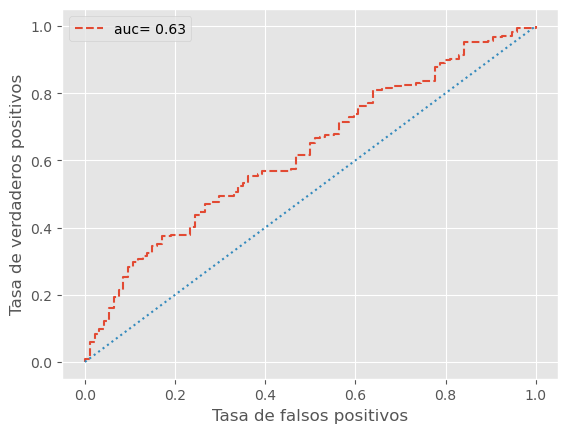

In [32]:
yhat_proba = grid_result.best_estimator_.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, yhat_proba)
auc = np.round(roc_auc_score(y_test, yhat_proba), 2)

plt.plot(fpr, tpr, '--', label=f'auc= {auc}') # Dibuja la curva ROC usando los valores de fpr y tpr calculados previamente:
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.plot([0, 1], [0, 1], ':')
plt.legend();